   area_sqft  bedrooms  bathrooms  house_age  parking_spaces  \
0       1256         2          2          7               1   
1       1219         2          2          1               1   
2       1752         2          1         22               3   
3       2518         3          3         18               2   
4       1453         5          4          8               1   

   distance_city_km  house_price  
0                 6       278012  
1                 4       265184  
2                24       314616  
3                 2       534904  
4                 8       378558  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   area_sqft         1000 non-null   int64
 1   bedrooms          1000 non-null   int64
 2   bathrooms         1000 non-null   int64
 3   house_age         1000 non-null   int64
 4   parking_spaces    1000 no

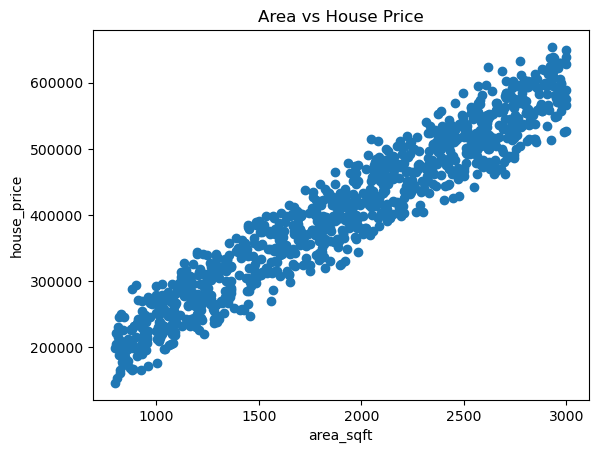

MSE: 69190856.41565655
R2 Score: 0.9953532743675092
Predicted house price: 488512.9923579143


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv(r"C:\Users\Adithyan\Downloads\house_price_dataset.csv")
print(df.head())
print(df.info())
print(df.isnull().sum())
plt.scatter(df["area_sqft"], df["house_price"])
plt.xlabel("area_sqft")
plt.ylabel("house_price")
plt.title("Area vs House Price")
plt.show()



features = ["area_sqft", "bedrooms", "bathrooms",
            "house_age", "parking_spaces", "distance_city_km"]
X = df[features]
y = df["house_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))


new_house = pd.DataFrame([{
    "area_sqft": 2200,
    "bedrooms": 4,
    "bathrooms": 3,
    "house_age": 8,
    "parking_spaces": 2,
    "distance_city_km": 6
}])
print("Predicted house price:", model.predict(new_house)[0])
